In [15]:
import torch
import matplotlib.pyplot as plt
import matplotlib.patches as patches

In [2]:
def calculate_iou(box1, box2):
    x1 = torch.maximum(box1[0], box2[0])
    y1 = torch.maximum(box1[1], box2[1])
    x2 = torch.minimum(box1[2], box2[2])
    y2 = torch.minimum(box1[3], box2[3])
    inter_width = torch.clamp(x2 - x1, min=0)
    inter_height = torch.clamp(y2 - y1, min=0)
    intersection = inter_width * inter_height
    area1 = (box1[2] - box1[0]) * (box1[3] - box1[1])
    area2 = (box2[2] - box2[0]) * (box2[3] - box2[1])
    union = area1 + area2 - intersection

    return torch.where(
        union > 0,
        intersection / union,
        torch.zeros_like(union)
    )

In [3]:
import requests
import zipfile
from pathlib import Path

RECORD_ID = "17552872"
BASE_DIR = Path("/content/apple_detection/dataset")
IMAGE_DIR = BASE_DIR / "images"
ANNOTATION_DIR = BASE_DIR / "annotation"
IMAGE_DIR.mkdir(parents=True, exist_ok=True)
ANNOTATION_DIR.mkdir(parents=True, exist_ok=True)

# fetch the dataset
api_url = f"https://zenodo.org/api/records/{RECORD_ID}"
response = requests.get(api_url, timeout=60)
response.raise_for_status()

metadata = response.json()

for filename, destination in [
    ("images.zip", IMAGE_DIR),
    ("annotation.zip", ANNOTATION_DIR)
]:
    file_info = next(
        f for f in metadata["files"]
        if f["key"] == filename
    )
    download_url = file_info["links"]["self"]
    zip_path = BASE_DIR / filename
    print(f"\nDownloading {filename}...")

    with requests.get(
        download_url,
        stream=True,
        timeout=120
    ) as r:
        r.raise_for_status()
        with open(zip_path, "wb") as f:
            for chunk in r.iter_content(chunk_size=1024 * 1024):
                if chunk:
                    f.write(chunk)
    print(f"Extracting {filename}...")
    with zipfile.ZipFile(zip_path, "r") as archive:
        archive.extractall(destination)
    zip_path.unlink()

print("\nDataset download and extraction complete.")


Extracting images.zip...

Extracting annotation.zip...

Dataset download and extraction complete.


In [4]:
from pathlib import Path

IMAGE_DIR = Path("/content/apple_detection/dataset/images/images")
ANNOTATION_DIR = Path("/content/apple_detection/dataset/annotation/annotation")

# get relevant files
image_files = [
    p for p in IMAGE_DIR.glob("*")
    if p.suffix.lower() in [".jpg", ".jpeg", ".png"]
    and not p.name.startswith("._")
]

annotation_files = [
    p for p in ANNOTATION_DIR.glob("*.txt")
    if not p.name.startswith("._")
]

image_stems = {p.stem for p in image_files}
annotation_stems = {p.stem for p in annotation_files}

print("Actual images:", len(image_files))
print("Actual annotations:", len(annotation_files))
print("Matching pairs:", len(image_stems & annotation_stems))
print("Missing annotations:", len(image_stems - annotation_stems))
print("Missing images:", len(annotation_stems - image_stems))


Actual images: 60
Actual annotations: 60
Matching pairs: 60
Missing annotations: 0
Missing images: 0


Selected image: 003fae7b-REF_2_E_Golden_MTP
Image dimensions: (2268, 4032)


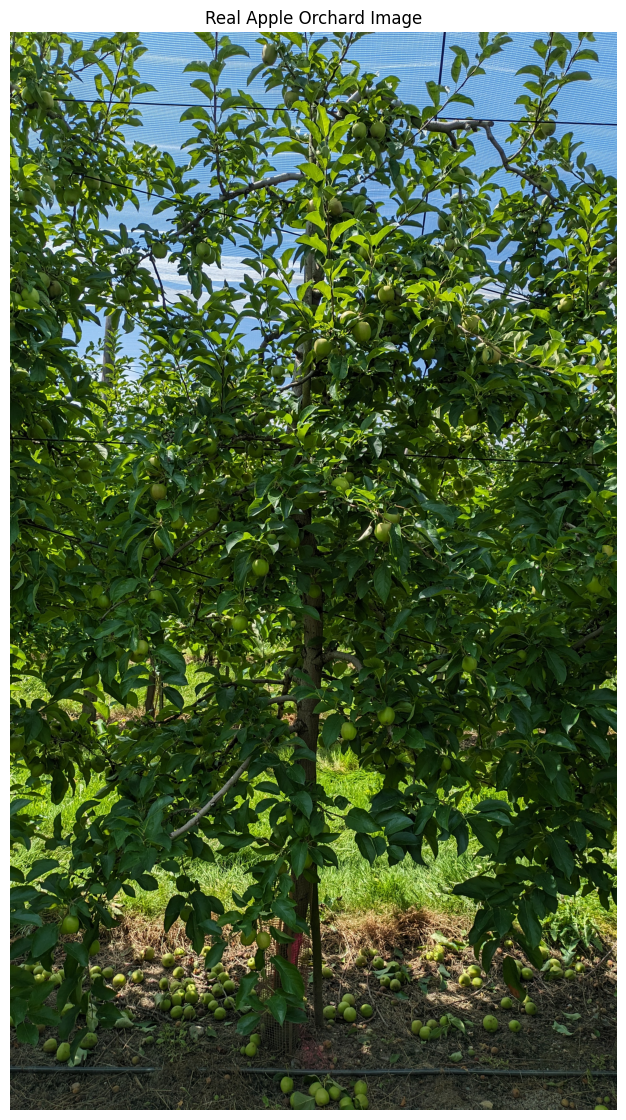

In [5]:
from PIL import Image
import matplotlib.pyplot as plt

sample_name = sorted(image_stems)[0]
IMAGE_PATH = IMAGE_DIR / f"{sample_name}.jpg"
ANNOTATION_PATH = ANNOTATION_DIR / f"{sample_name}.txt"
image = Image.open(IMAGE_PATH).convert("RGB")

print("Selected image:", sample_name)
print("Image dimensions:", image.size)

plt.figure(figsize=(10, 14))
plt.imshow(image)
plt.title("Real Apple Orchard Image")
plt.axis("off")
plt.show()

In [6]:
import numpy as np
import torch

# Read actual apple annotations
apple_boxes = []

with open(ANNOTATION_PATH, "r") as f:
    for line in f:
        values = list(map(float, line.strip().split()))
        if int(values[0]) == 0:
            cx, cy, w, h = values[1:5]
            x1 = (cx - w / 2) * image.width
            y1 = (cy - h / 2) * image.height
            x2 = (cx + w / 2) * image.width
            y2 = (cy + h / 2) * image.height
            apple_boxes.append([x1, y1, x2, y2])

apple_boxes = np.array(apple_boxes, dtype=np.float32)
print("Total annotated apples:", len(apple_boxes))

Total annotated apples: 162


In [7]:
# calculate the centre of each bounding box
centers = np.column_stack((
    (apple_boxes[:, 0] + apple_boxes[:, 2]) / 2,
    (apple_boxes[:, 1] + apple_boxes[:, 3]) / 2
))

normalized_centers = centers / np.array(
    [image.width, image.height]
)

# get the apple nearest this center
image_center = np.array([0.5, 0.5])

first_idx = np.argmin(
    np.linalg.norm(normalized_centers - image_center, axis=1)
)

selected_indices = [int(first_idx)]
# select two more apples far away from the selected ones
while len(selected_indices) < 3:
    distances = np.linalg.norm(
        normalized_centers[:, None, :] -
        normalized_centers[selected_indices][None, :, :],
        axis=2
    )
    min_distances = distances.min(axis=1)
    min_distances[selected_indices] = -1
    selected_indices.append(int(np.argmax(min_distances)))

ground_truth_boxes = torch.tensor(
    apple_boxes[selected_indices],
    dtype=torch.float32
)

print("Selected annotation indices:", selected_indices)
print("Ground-truth boxes:\n", ground_truth_boxes)

Selected annotation indices: [108, 0, 13]
Ground-truth boxes:
 tensor([[1113.3042, 2069.8906, 1164.2126, 2118.4851],
        [  41.6524,  200.1627,  106.4449,  273.0543],
        [2213.6206,  790.4691, 2268.0000,  852.7162]])


In [8]:
predicted_boxes = []
scores = []

# assumptions for simulations

confidence_values = [
    [0.96, 0.84, 0.77],
    [0.93, 0.86, 0.75],
    [0.98, 0.83, 0.72]
]

shifts = [
    (0.00, 0.00),   # exact
    (0.08, 0.05),   # slight shift
    (-0.10, -0.08)  # another shifted prediction
]

for i, gt in enumerate(ground_truth_boxes):
    x1, y1, x2, y2 = gt.tolist()
    width = x2 - x1
    height = y2 - y1
    for j, (dx, dy) in enumerate(shifts):
        shift_x = dx * width
        shift_y = dy * height
        prediction = [
            x1 + shift_x,
            y1 + shift_y,
            x2 + shift_x,
            y2 + shift_y
        ]
        predicted_boxes.append(prediction)
        scores.append(confidence_values[i][j])

boxes = torch.tensor(predicted_boxes, dtype=torch.float32)
scores = torch.tensor(scores, dtype=torch.float32)

print("Candidate detections:", len(boxes))
print("Confidence scores:", scores.tolist())

Candidate detections: 9
Confidence scores: [0.9599999785423279, 0.8399999737739563, 0.7699999809265137, 0.9300000071525574, 0.8600000143051147, 0.75, 0.9800000190734863, 0.8299999833106995, 0.7200000286102295]


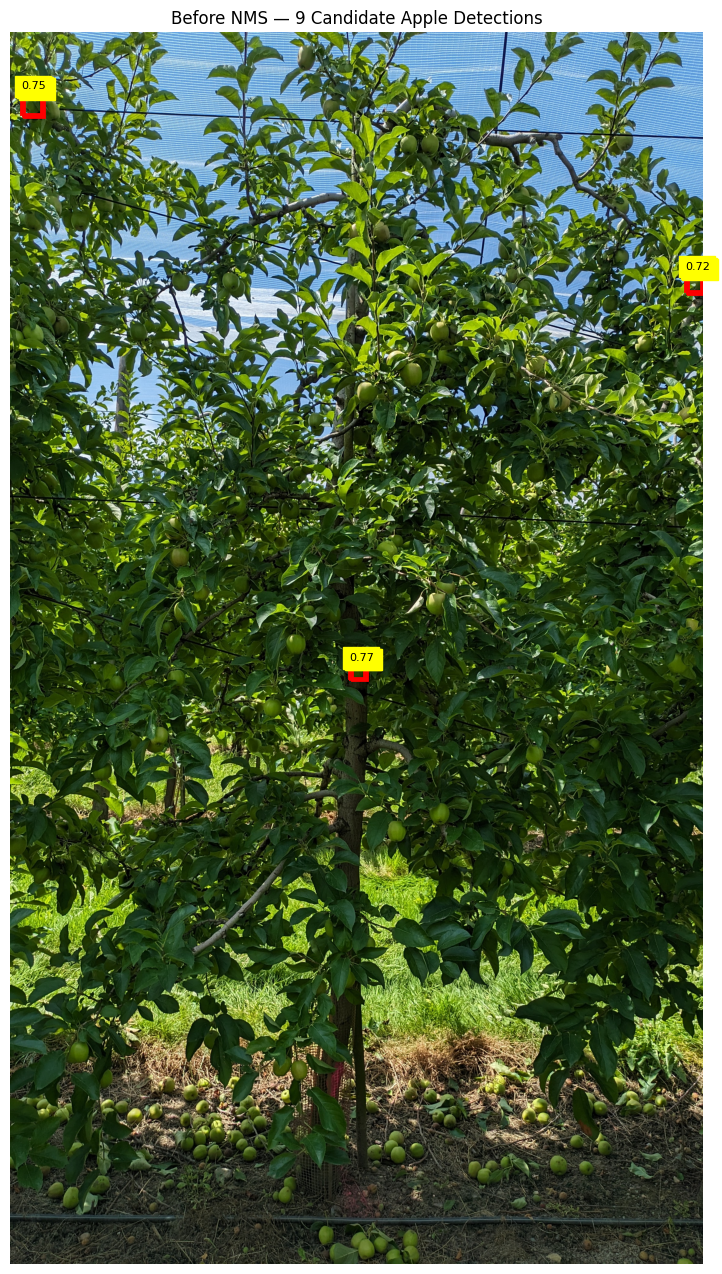

In [9]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches

def visualize_detections(image, boxes, scores, title, color):
    fig, ax = plt.subplots(figsize=(12, 16))
    ax.imshow(image)
    for i, box in enumerate(boxes):
        x1, y1, x2, y2 = box.tolist()
        rect = patches.Rectangle(
            (x1, y1),
            x2 - x1,
            y2 - y1,
            linewidth=2,
            edgecolor=color,
            facecolor="none"
        )
        ax.add_patch(rect)
        ax.text(
            x1,
            max(0, y1 - 8),
            f"{scores[i].item():.2f}",
            color="black",
            fontsize=8,
            backgroundcolor="yellow"
        )

    ax.set_title(title)
    ax.axis("off")
    plt.show()


visualize_detections(
    image,
    boxes,
    scores,
    "Before NMS — 9 Candidate Apple Detections",
    "red"
)

In [10]:
def nms(boxes, scores, thr=0.5):
    # sort detections by confidence
    order = scores.argsort(descending=True).tolist()
    keep = []
    while order:
        # get the highest confidence prediction
        i = order.pop(0)
        keep.append(i)
        remaining = []
        # compare against all detections
        for j in order:
            overlap = calculate_iou(boxes[i], boxes[j])
            # dont consider boxes with IoU >= threshold
            if overlap.item() < thr:
                remaining.append(j)
        order = remaining

    return keep

In [11]:
iou_threshold = 0.5

kept_indices = nms(
    boxes,
    scores,
    thr=iou_threshold
)
kept_boxes = boxes[kept_indices]
kept_scores = scores[kept_indices]

print("Before NMS:", len(boxes))
print("After NMS:", len(kept_boxes))
print("\nSelected detections:")

for i in kept_indices:
    print(
        f"Detection {i} | Confidence: {scores[i].item():.2f}"
    )

Before NMS: 9
After NMS: 3

Selected detections:
Detection 6 | Confidence: 0.98
Detection 0 | Confidence: 0.96
Detection 3 | Confidence: 0.93


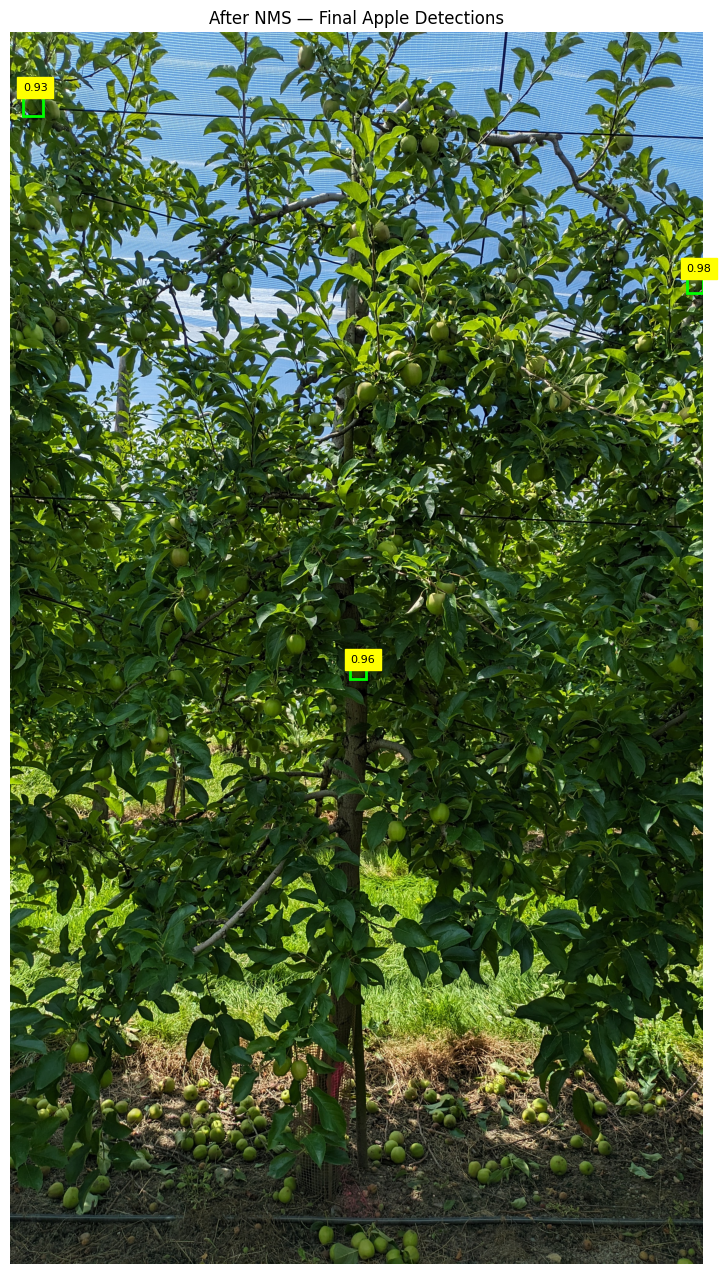

In [12]:
visualize_detections(
    image,
    kept_boxes,
    kept_scores,
    "After NMS — Final Apple Detections",
    "lime"
)

In [13]:
thresholds = [0.1, 0.3, 0.5, 0.7, 0.9]

for threshold in thresholds:
    selected = nms(
        boxes,
        scores,
        thr=threshold
    )
    print(
        f"IoU threshold: {threshold:.1f} "
        f"| Remaining detections: {len(selected)}"
    )

IoU threshold: 0.1 | Remaining detections: 3
IoU threshold: 0.3 | Remaining detections: 3
IoU threshold: 0.5 | Remaining detections: 3
IoU threshold: 0.7 | Remaining detections: 3
IoU threshold: 0.9 | Remaining detections: 9


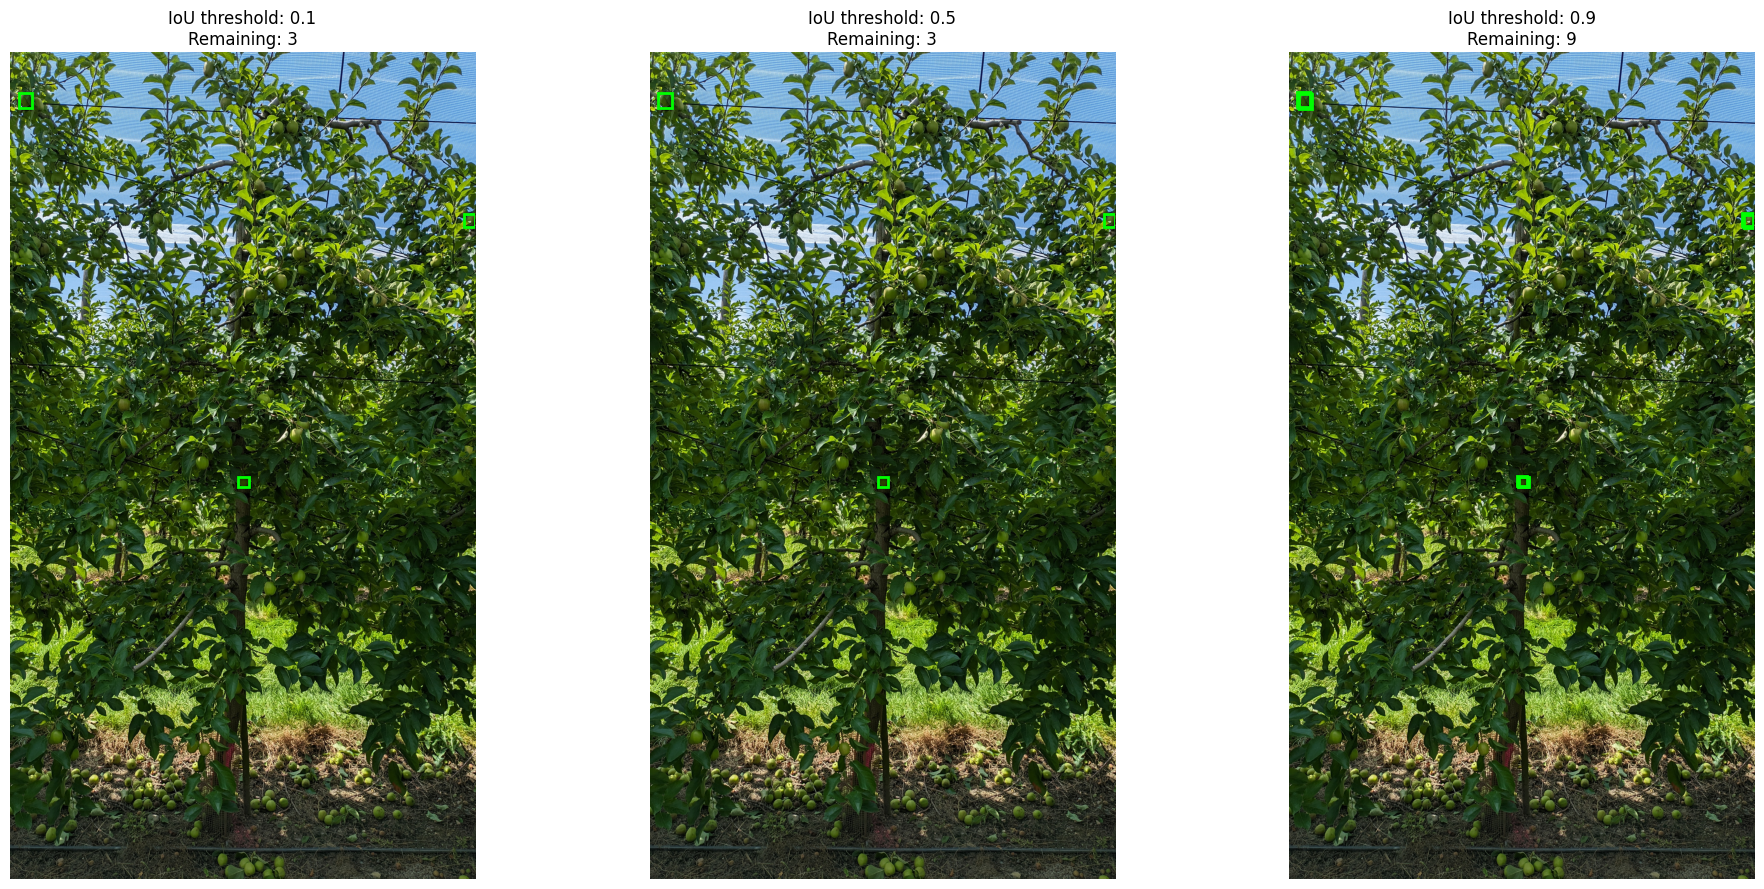

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(20, 9))

for ax, threshold in zip(axes, [0.1, 0.5, 0.9]):
    selected = nms(boxes, scores, thr=threshold)
    ax.imshow(image)
    for i in selected:
        x1, y1, x2, y2 = boxes[i].tolist()
        rect = patches.Rectangle(
            (x1, y1),
            x2 - x1,
            y2 - y1,
            linewidth=2,
            edgecolor="lime",
            facecolor="none"
        )
        ax.add_patch(rect)

    ax.set_title(
        f"IoU threshold: {threshold}\n"
        f"Remaining: {len(selected)}"
    )

    ax.axis("off")

plt.tight_layout()
plt.show()